In [51]:
import pandas as pd
import numpy as np

import statsmodels.api as sm

from statsmodels.tools import add_constant

In [52]:
df = pd.read_spss(

    r'G:\Documents\Book\1\4th Year\4th\1822021 (Project)\SPSS\Data Entry_Finallll_2_48.sav'
)

In [76]:
import os

# Create results folder

output_folder = r'G:\\Documents\\Book\\1\\4th Year\\4th\\1822021 (Project)\\Results'

os.makedirs(output_folder, exist_ok=True)

print("Results folder ready:")
print(output_folder)

Results folder ready:
G:\\Documents\\Book\\1\\4th Year\\4th\\1822021 (Project)\\Results


In [77]:
df['CMD_binary'] = df['CMD'].astype(str)

df['CMD_binary'] = df['CMD_binary'].map({

    'No CMD': 0,
    'CMD Present': 1
})

print(df['CMD_binary'].value_counts())

CMD_binary
0    360
1    340
Name: count, dtype: int64


In [78]:
model1_vars = [

    'Gender',

    'University_name',

    'Physical_activity_level'
]

# Create dataset

model1_df = df[model1_vars + ['CMD_binary']].dropna()

# One-hot encoding

X1 = pd.get_dummies(

    model1_df[model1_vars],

    drop_first=True
)

y1 = model1_df['CMD_binary']

# Add constant

X1 = add_constant(X1)

# Convert to numeric

X1 = X1.astype(float)

# Logistic regression

model1 = sm.Logit(y1, X1).fit()

print(model1.summary())

Optimization terminated successfully.
         Current function value: 0.674190
         Iterations 4
                           Logit Regression Results                           
Dep. Variable:             CMD_binary   No. Observations:                  700
Model:                          Logit   Df Residuals:                      690
Method:                           MLE   Df Model:                            9
Date:                Sun, 17 May 2026   Pseudo R-squ.:                 0.02678
Time:                        17:07:35   Log-Likelihood:                -471.93
converged:                       True   LL-Null:                       -484.92
Covariance Type:            nonrobust   LLR p-value:                  0.002067
                                                     coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------------------------
const                               

In [79]:
model2_vars = [

    'Average_DD_Use_Time',

    'Do_Multitask',

    'Excessive_ST_affect_AP',

    'Screen_use_1hr_before_bedtime'
]

model2_df = df[model2_vars + ['CMD_binary']].dropna()

X2 = pd.get_dummies(

    model2_df[model2_vars],

    drop_first=True
)

y2 = model2_df['CMD_binary']

X2 = add_constant(X2)

X2 = X2.astype(float)

model2 = sm.Logit(y2, X2).fit()

print(model2.summary())

Optimization terminated successfully.
         Current function value: 0.635117
         Iterations 6
                           Logit Regression Results                           
Dep. Variable:             CMD_binary   No. Observations:                  700
Model:                          Logit   Df Residuals:                      688
Method:                           MLE   Df Model:                           11
Date:                Sun, 17 May 2026   Pseudo R-squ.:                 0.08318
Time:                        17:07:36   Log-Likelihood:                -444.58
converged:                       True   LL-Null:                       -484.92
Covariance Type:            nonrobust   LLR p-value:                 1.094e-12
                                              coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------------
const                                      -0.9750

In [80]:
model3_vars = [

    'Sleep_Pattern_Change',

    'Varsity_hr_tiredness',

    'Feel_tired_after_Use_DD'
]

model3_df = df[model3_vars + ['CMD_binary']].dropna()

X3 = pd.get_dummies(

    model3_df[model3_vars],

    drop_first=True
)

y3 = model3_df['CMD_binary']

X3 = add_constant(X3)

X3 = X3.astype(float)

model3 = sm.Logit(y3, X3).fit()

print(model3.summary())

         Current function value: 0.664521
         Iterations: 35
                           Logit Regression Results                           
Dep. Variable:             CMD_binary   No. Observations:                  700
Model:                          Logit   Df Residuals:                      689
Method:                           MLE   Df Model:                           10
Date:                Sun, 17 May 2026   Pseudo R-squ.:                 0.04073
Time:                        17:07:37   Log-Likelihood:                -465.17
converged:                      False   LL-Null:                       -484.92
Covariance Type:            nonrobust   LLR p-value:                 2.071e-05
                                                           coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------------------------------
const                                                   19.2

C:\Users\M R Computer\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


In [81]:
final_vars = [

    'Average_DD_Use_Time',

    'Sleep_Pattern_Change',

    'Varsity_hr_tiredness',

    'Impact_Learning_Ability',

    'Physical_activity_level',

    'Screen_use_1hr_before_bedtime',

    'Experienced_Headaches_for_ST'
]

final_df = df[final_vars + ['CMD_binary']].dropna()

X4 = pd.get_dummies(

    final_df[final_vars],

    drop_first=True
)

y4 = final_df['CMD_binary']

X4 = add_constant(X4)

X4 = X4.astype(float)

final_model = sm.Logit(y4, X4).fit()

print(final_model.summary())

         Current function value: 0.618476
         Iterations: 35
                           Logit Regression Results                           
Dep. Variable:             CMD_binary   No. Observations:                  700
Model:                          Logit   Df Residuals:                      681
Method:                           MLE   Df Model:                           18
Date:                Sun, 17 May 2026   Pseudo R-squ.:                  0.1072
Time:                        17:07:38   Log-Likelihood:                -432.93
converged:                      False   LL-Null:                       -484.92
Covariance Type:            nonrobust   LLR p-value:                 4.130e-14
                                                           coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------------------------------
const                                                   16.7

C:\Users\M R Computer\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


In [82]:
params = final_model.params

conf = final_model.conf_int()

conf['OR'] = params

conf.columns = [

    '2.5%',
    '97.5%',
    'OR'
]

# Odds ratios

OR_table = np.exp(conf)

# P-values

OR_table['p-value'] = final_model.pvalues

print("\nADJUSTED ODDS RATIOS")
print(OR_table)

# Save table

OR_table.to_csv(

    'Final_Logistic_Regression_OR_Table.csv'
)


ADJUSTED ODDS RATIOS
                                                        2.5%     97.5%  \
const                                               0.000000       inf   
Average_DD_Use_Time_4-6                             1.085017  2.606826   
Average_DD_Use_Time_<2                              0.108419  1.047464   
Average_DD_Use_Time_>6                              2.651855  6.806041   
Sleep_Pattern_Change_Disturbed or poor-quality ...  0.629289  1.716994   
Sleep_Pattern_Change_No noticeable change           0.432938  1.182275   
Sleep_Pattern_Change_Reduce sleep duration          0.455970  1.144669   
Varsity_hr_tiredness_Always                         0.000000       inf   
Varsity_hr_tiredness_Never                          0.000000       inf   
Varsity_hr_tiredness_Often                          0.000000       inf   
Varsity_hr_tiredness_Sometimes                      0.000000       inf   
Impact_Learning_Ability_Yes, negatively             1.084483  3.074216   
Impact_Learning_

C:\Users\M R Computer\anaconda3\Lib\site-packages\pandas\core\internals\blocks.py:395: RuntimeWarning: overflow encountered in exp
  result = func(self.values, **kwargs)



CMD PREVALENCE (%)
CMD
No CMD         51.428571
CMD Present    48.571429
Name: proportion, dtype: float64

Figure exported successfully.

Saved Location:
G:\Documents\Book\1\4th Year\4th\1822021 (Project)\Results\CMD_Prevalence_BarChart.png

Table exported successfully.


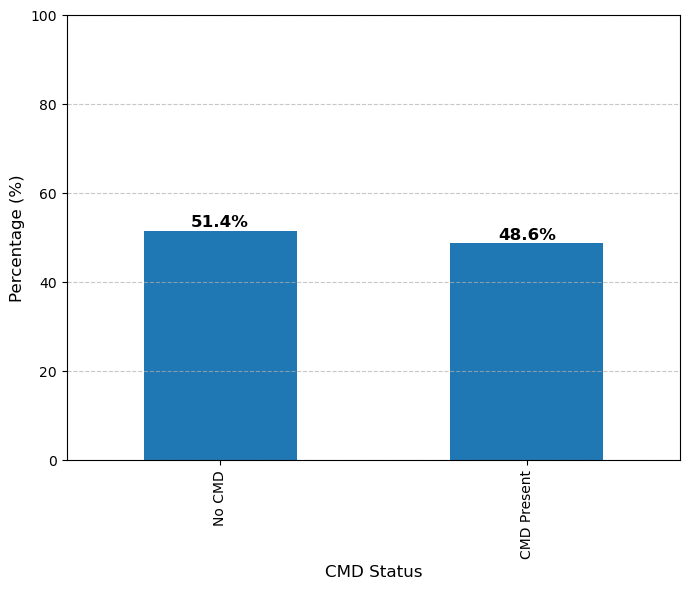

In [95]:
# =========================================================
# CMD PREVALENCE BAR CHART
# PUBLICATION-QUALITY FIGURE + EXPORT
# =========================================================

import os
import pandas as pd
import matplotlib.pyplot as plt


# =========================================================
# 1. CALCULATE CMD PREVALENCE
# =========================================================

cmd_prev = df['CMD'].value_counts(

    normalize=True
) * 100


# =========================================================
# 2. DISPLAY PREVALENCE
# =========================================================

print("\nCMD PREVALENCE (%)")

print(cmd_prev)


# =========================================================
# 3. DEFINE SAVE LOCATION
# =========================================================

OUTPUT_DIR = r'G:\Documents\Book\1\4th Year\4th\1822021 (Project)\Results'

os.makedirs(OUTPUT_DIR, exist_ok=True)


# =========================================================
# 4. CREATE BAR CHART
# =========================================================

ax = cmd_prev.plot(

    kind='bar',

    figsize=(7,6)
)


# =========================================================
# 5. ADD PERCENTAGE LABELS
# =========================================================

for i, value in enumerate(cmd_prev):

    ax.text(

        i,
        value + 1,

        f'{value:.1f}%',

        ha='center',
        fontsize=12,
        fontweight='bold'
    )


# =========================================================
# 6. LABELS
# =========================================================

plt.ylabel(

    'Percentage (%)',
    fontsize=12
)

plt.xlabel(

    'CMD Status',
    fontsize=12
)


# =========================================================
# 7. Y-AXIS LIMIT
# =========================================================

plt.ylim(0, 100)


# =========================================================
# 8. GRID
# =========================================================

plt.grid(

    axis='y',
    linestyle='--',
    alpha=0.7
)


# =========================================================
# 9. SAVE FIGURE
# =========================================================

plt.tight_layout()

plt.savefig(

    os.path.join(

        OUTPUT_DIR,

        'CMD_Prevalence_BarChart.png'
    ),

    dpi=300,
    bbox_inches='tight'
)

print("\nFigure exported successfully.")

print("\nSaved Location:")

print(

    os.path.join(

        OUTPUT_DIR,

        'CMD_Prevalence_BarChart.png'
    )
)


# =========================================================
# 10. SAVE TABLE
# =========================================================

cmd_prev.to_csv(

    os.path.join(

        OUTPUT_DIR,

        'CMD_Prevalence_Table.csv'
    )
)

print("\nTable exported successfully.")


# =========================================================
# 11. SHOW FIGURE
# =========================================================

plt.show()


CMD vs DIGITAL DEVICE USE TIME (%)
CMD                  CMD Present     No CMD
Average_DD_Use_Time                        
<2                     12.903226  87.096774
2-4                    33.093525  66.906475
4-6                    44.755245  55.244755
>6                     66.393443  33.606557

Figure exported successfully.

Saved Location:
G:\Documents\Book\1\4th Year\4th\1822021 (Project)\Results\CMD_vs_Digital_Device_Use_Time.png

Table exported successfully.


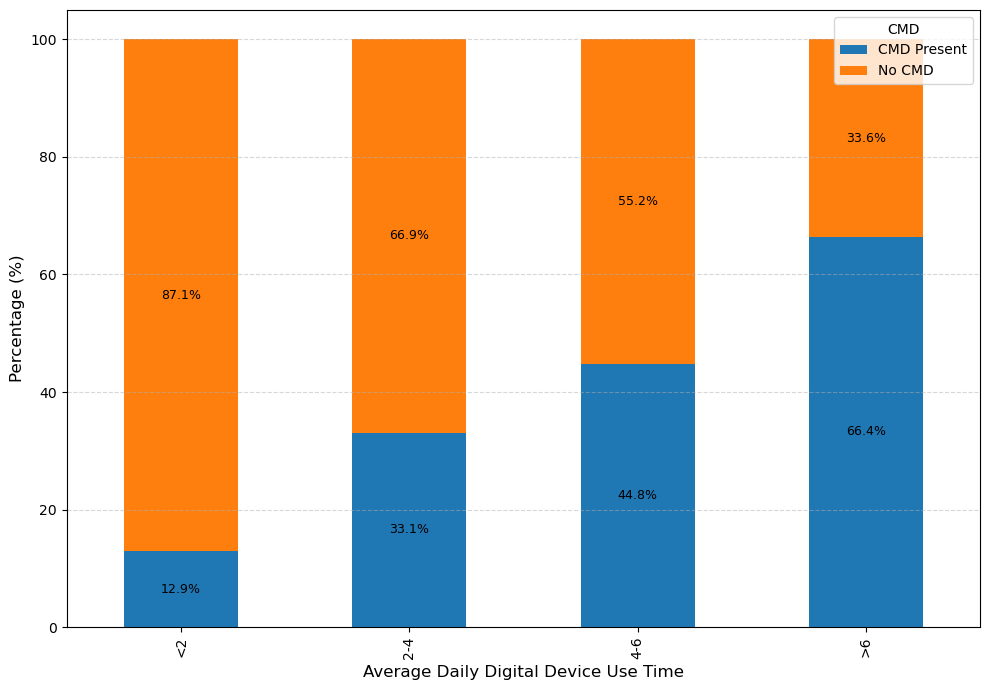

In [97]:
# =========================================================
# CMD vs DIGITAL DEVICE USE TIME
# STACKED BAR CHART + EXPORT
# =========================================================

import os
import pandas as pd
import matplotlib.pyplot as plt


# =========================================================
# 1. CREATE CROSSTAB TABLE
# =========================================================

cmd_table = pd.crosstab(

    df['Average_DD_Use_Time'],
    df['CMD'],

    normalize='index'
) * 100


# =========================================================
# 2. REORDER CATEGORIES
# =========================================================

desired_order = [

    '<2',
    '2-4',
    '4-6',
    '>6'
]

cmd_table = cmd_table.reindex(desired_order)


# =========================================================
# 3. DISPLAY TABLE
# =========================================================

print("\nCMD vs DIGITAL DEVICE USE TIME (%)")

print(cmd_table)


# =========================================================
# 4. DEFINE OUTPUT DIRECTORY
# =========================================================

OUTPUT_DIR = r'G:\Documents\Book\1\4th Year\4th\1822021 (Project)\Results'

os.makedirs(OUTPUT_DIR, exist_ok=True)


# =========================================================
# 5. CREATE STACKED BAR CHART
# =========================================================

ax = cmd_table.plot(

    kind='bar',

    stacked=True,

    figsize=(10,7)
)


# =========================================================
# 6. LABELS
# =========================================================

plt.xlabel(

    'Average Daily Digital Device Use Time',
    fontsize=12
)

plt.ylabel(

    'Percentage (%)',
    fontsize=12
)


# =========================================================
# 7. LEGEND
# =========================================================

plt.legend(

    title='CMD'
)


# =========================================================
# 8. ADD PERCENTAGE LABELS
# =========================================================

for container in ax.containers:

    ax.bar_label(

        container,

        fmt='%.1f%%',

        label_type='center',

        fontsize=9
    )


# =========================================================
# 9. GRID
# =========================================================

plt.grid(

    axis='y',
    linestyle='--',
    alpha=0.5
)


# =========================================================
# 10. SAVE FIGURE
# =========================================================

plt.tight_layout()

plt.savefig(

    os.path.join(

        OUTPUT_DIR,

        'CMD_vs_Digital_Device_Use_Time.png'
    ),

    dpi=300,
    bbox_inches='tight'
)

print("\nFigure exported successfully.")

print("\nSaved Location:")

print(

    os.path.join(

        OUTPUT_DIR,

        'CMD_vs_Digital_Device_Use_Time.png'
    )
)


# =========================================================
# 11. SAVE TABLE
# =========================================================

cmd_table.to_csv(

    os.path.join(

        OUTPUT_DIR,

        'CMD_vs_Digital_Device_Use_Time_Table.csv'
    )
)

print("\nTable exported successfully.")


# =========================================================
# 12. SHOW FIGURE
# =========================================================

plt.show()


CMD SEVERITY vs DEVICE USE TIME (%)
CMD_Severity         Mild CMD  Moderate CMD     No CMD  Severe CMD
Average_DD_Use_Time                                               
<2                   3.225806      9.677419  87.096774    0.000000
2-4                  6.474820      9.352518  67.625899   16.546763
4-6                  1.398601     17.132867  55.244755   26.223776
>6                   2.459016     18.032787  33.606557   45.901639

Figure exported successfully.

Saved Location:
G:\Documents\Book\1\4th Year\4th\1822021 (Project)\Results\CMD_Severity_vs_Digital_Device_Use.png

Table exported successfully.


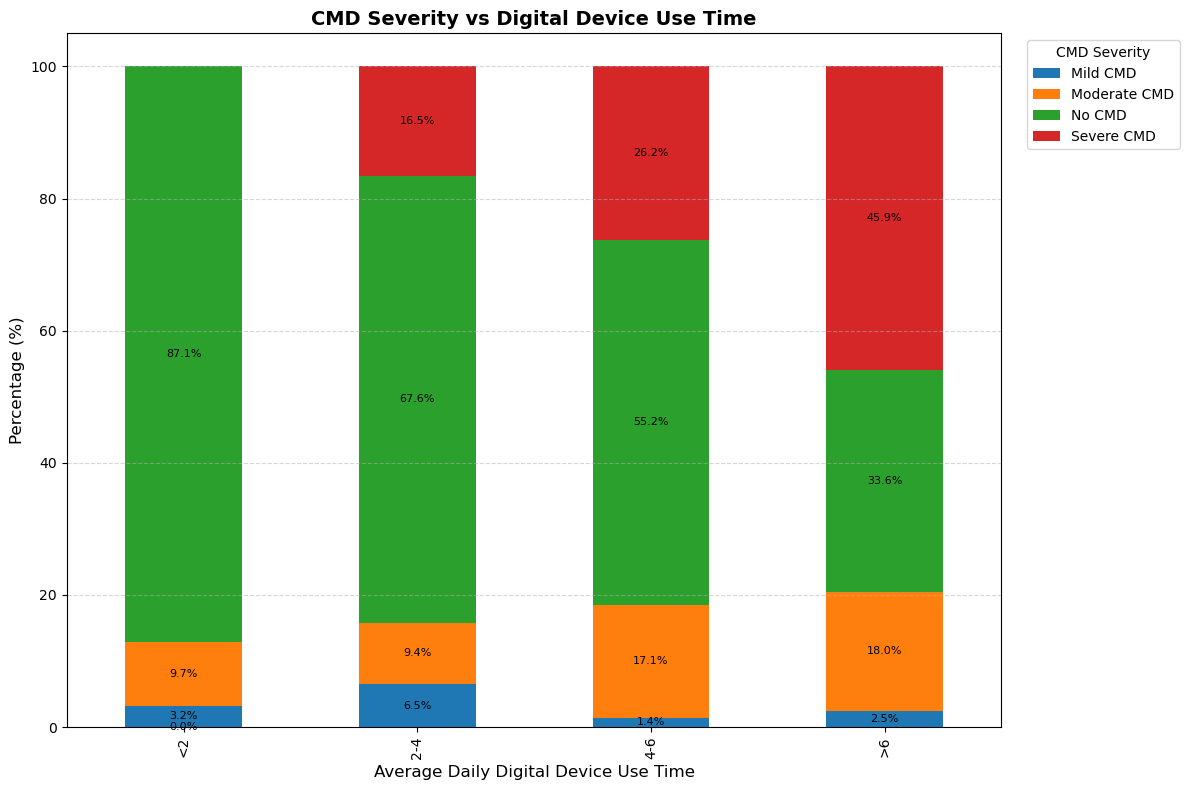

In [100]:
# =========================================================
# CMD SEVERITY vs DIGITAL DEVICE USE TIME
# STACKED BAR CHART + EXPORT
# PUBLICATION-QUALITY FIGURE
# =========================================================

import os
import pandas as pd
import matplotlib.pyplot as plt


# =========================================================
# 1. CREATE CROSSTAB TABLE
# =========================================================

severity_table = pd.crosstab(

    df['Average_DD_Use_Time'],
    df['CMD_Severity'],

    normalize='index'
) * 100


# =========================================================
# 2. REORDER CATEGORIES
# =========================================================

desired_order = [

    '<2',
    '2-4',
    '4-6',
    '>6'
]

severity_table = severity_table.reindex(desired_order)


# =========================================================
# 3. DISPLAY TABLE
# =========================================================

print("\nCMD SEVERITY vs DEVICE USE TIME (%)")

print(severity_table)


# =========================================================
# 4. DEFINE OUTPUT DIRECTORY
# =========================================================

OUTPUT_DIR = r'G:\Documents\Book\1\4th Year\4th\1822021 (Project)\Results'

os.makedirs(OUTPUT_DIR, exist_ok=True)


# =========================================================
# 5. CREATE STACKED BAR CHART
# =========================================================

ax = severity_table.plot(

    kind='bar',

    stacked=True,

    figsize=(12,8)
)


# =========================================================
# 6. LABELS
# =========================================================

plt.xlabel(

    'Average Daily Digital Device Use Time',
    fontsize=12
)

plt.ylabel(

    'Percentage (%)',
    fontsize=12
)

plt.title(

    'CMD Severity vs Digital Device Use Time',

    fontsize=14,
    fontweight='bold'
)


# =========================================================
# 7. LEGEND
# =========================================================

plt.legend(

    title='CMD Severity',

    bbox_to_anchor=(1.02, 1),

    loc='upper left'
)


# =========================================================
# 8. ADD PERCENTAGE LABELS
# =========================================================

for container in ax.containers:

    ax.bar_label(

        container,

        fmt='%.1f%%',

        label_type='center',

        fontsize=8
    )


# =========================================================
# 9. GRID
# =========================================================

plt.grid(

    axis='y',
    linestyle='--',
    alpha=0.5
)


# =========================================================
# 10. SAVE FIGURE
# =========================================================

plt.tight_layout()

plt.savefig(

    os.path.join(

        OUTPUT_DIR,

        'CMD_Severity_vs_Digital_Device_Use.png'
    ),

    dpi=300,
    bbox_inches='tight'
)

print("\nFigure exported successfully.")

print("\nSaved Location:")

print(

    os.path.join(

        OUTPUT_DIR,

        'CMD_Severity_vs_Digital_Device_Use.png'
    )
)


# =========================================================
# 11. SAVE TABLE
# =========================================================

severity_table.to_csv(

    os.path.join(

        OUTPUT_DIR,

        'CMD_Severity_vs_Digital_Device_Use_Table.csv'
    )
)

print("\nTable exported successfully.")


# =========================================================
# 12. SHOW FIGURE
# =========================================================

plt.show()


TOP 20 IMPORTANT VARIABLES
                                      Variable  Importance
30                Overall_Health_Worsening_Yes    0.050030
12               Average_DD_Use_Time_greater_6    0.048577
37                 Varsity_hr_tiredness_Always    0.031915
11                  Average_DD_Use_Time_less_2    0.029408
2           University_name_Islamic_University    0.029300
22            Experienced_Headaches_for_ST_Yes    0.028889
18               Feel_tired_after_Use_DD_Often    0.028346
35   Sleep_Pattern_Change_No_noticeable_change    0.027780
33     Screen_use_1hr_before_bedtime_Sometimes    0.027426
28     Impact_Learning_Ability_Yes,_negatively    0.026857
21                   Experienced_ES_for_ST_Yes    0.026305
0                                  Gender_Male    0.026236
15                      Do_Multitask_Sometimes    0.026032
36  Sleep_Pattern_Change_Reduce_sleep_duration    0.025967
32         Screen_use_1hr_before_bedtime_Often    0.025959
40              Varsity_hr_t

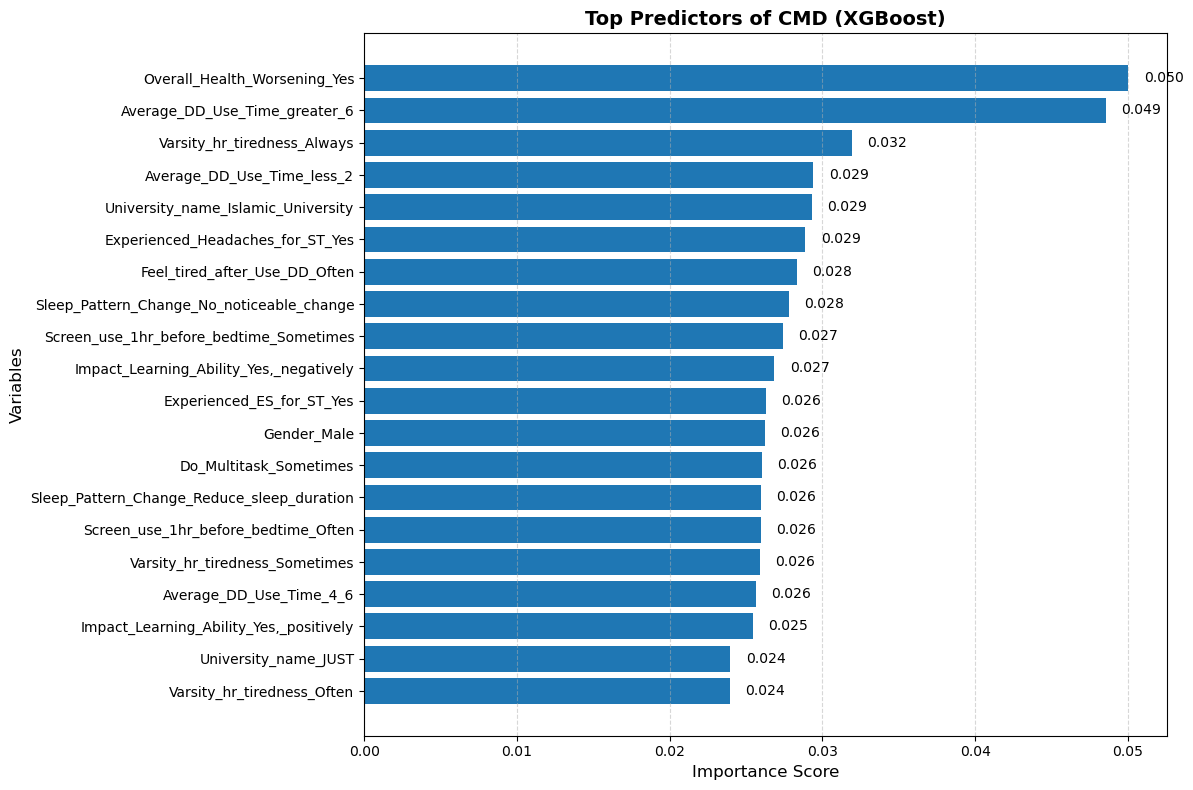

In [98]:
# =========================================================
# TOP 20 PREDICTORS OF CMD
# XGBOOST FEATURE IMPORTANCE
# EXPORT PUBLICATION-QUALITY FIGURE
# =========================================================

import os
import pandas as pd
import matplotlib.pyplot as plt


# =========================================================
# 1. SELECT TOP 20 VARIABLES
# =========================================================

top20 = importance_df.head(20)


# =========================================================
# 2. DISPLAY TABLE
# =========================================================

print("\nTOP 20 IMPORTANT VARIABLES")

print(top20)


# =========================================================
# 3. DEFINE OUTPUT DIRECTORY
# =========================================================

OUTPUT_DIR = r'G:\Documents\Book\1\4th Year\4th\1822021 (Project)\Results'

os.makedirs(OUTPUT_DIR, exist_ok=True)


# =========================================================
# 4. CREATE FEATURE IMPORTANCE PLOT
# =========================================================

plt.figure(figsize=(12,8))

plt.barh(

    top20['Variable'],
    top20['Importance']
)


# =========================================================
# 5. ADD IMPORTANCE LABELS
# =========================================================

for index, value in enumerate(top20['Importance']):

    plt.text(

        value + 0.001,
        index,

        f'{value:.3f}',

        va='center',
        fontsize=10
    )


# =========================================================
# 6. LABELS
# =========================================================

plt.xlabel(

    'Importance Score',
    fontsize=12
)

plt.ylabel(

    'Variables',
    fontsize=12
)

plt.title(

    'Top Predictors of CMD (XGBoost)',

    fontsize=14,
    fontweight='bold'
)


# =========================================================
# 7. INVERT Y-AXIS
# =========================================================

plt.gca().invert_yaxis()


# =========================================================
# 8. GRID
# =========================================================

plt.grid(

    axis='x',
    linestyle='--',
    alpha=0.5
)


# =========================================================
# 9. SAVE FIGURE
# =========================================================

plt.tight_layout()

plt.savefig(

    os.path.join(

        OUTPUT_DIR,

        'Top20_CMD_Predictors_XGBoost.png'
    ),

    dpi=300,
    bbox_inches='tight'
)

print("\nFeature importance figure exported successfully.")

print("\nSaved Location:")

print(

    os.path.join(

        OUTPUT_DIR,

        'Top20_CMD_Predictors_XGBoost.png'
    )
)


# =========================================================
# 10. SAVE TABLE
# =========================================================

top20.to_csv(

    os.path.join(

        OUTPUT_DIR,

        'Top20_CMD_Predictors_Table.csv'
    ),

    index=False
)

print("\nTop 20 predictors table exported successfully.")


# =========================================================
# 11. SHOW FIGURE
# =========================================================

plt.show()


RESULTS WILL BE SAVED IN:
G:\Documents\Book\1\4th Year\4th\1822021 (Project)\Results

Feature importance table saved.
Top 20 predictors saved.
Model performance saved.
Classification report saved.
Confusion matrix table saved.


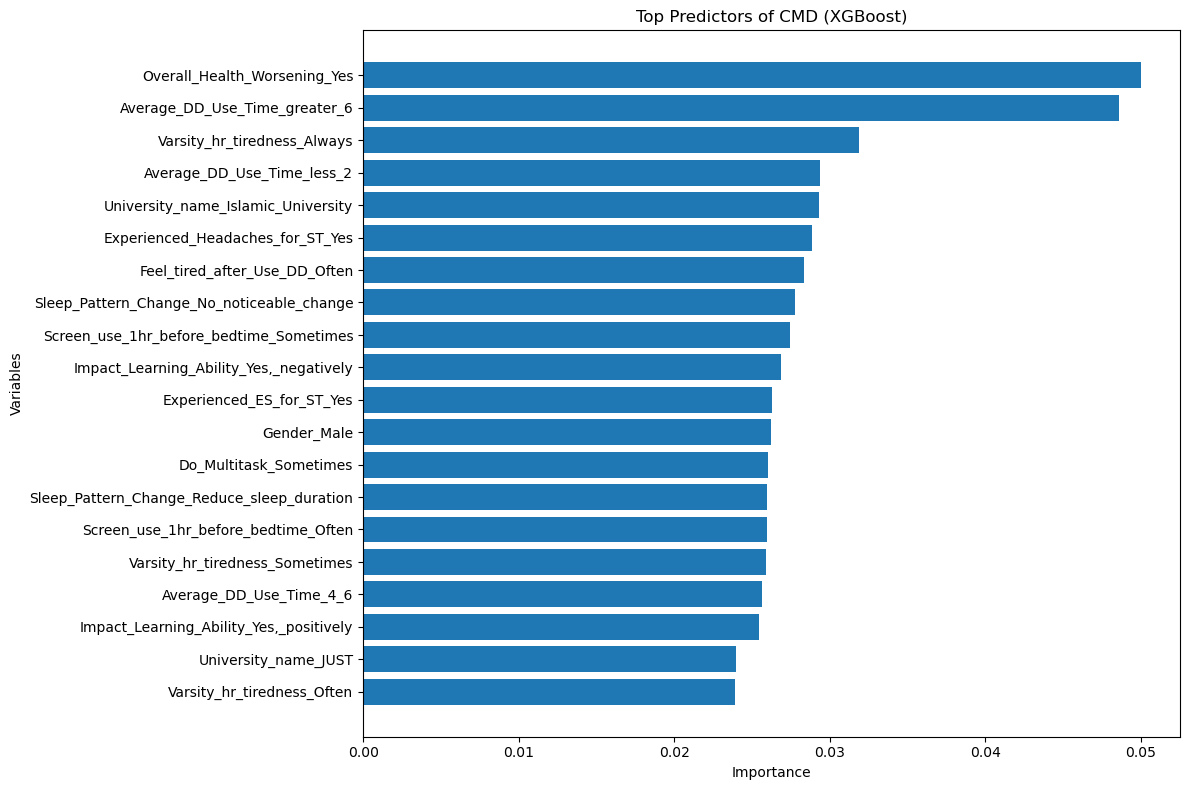

Feature importance figure exported.


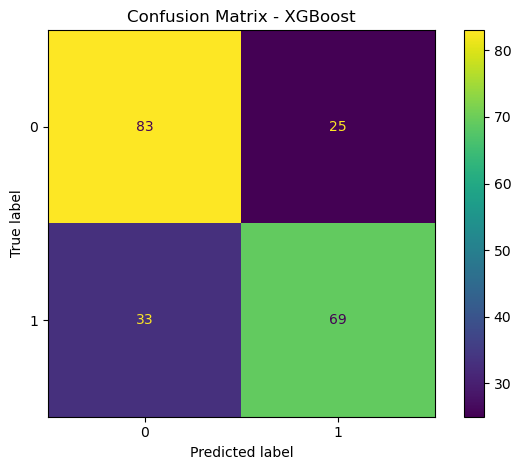

Confusion matrix figure exported.
Cross-validation results saved.
Best hyperparameters saved.

ALL RESULTS EXPORTED SUCCESSFULLY


EXPORTED FILES

CSV FILES:
1. XGBoost_CMD_Feature_Importance.csv
2. Top20_CMD_Predictors.csv
3. XGBoost_Model_Performance.csv
4. XGBoost_Classification_Report.csv
5. XGBoost_Confusion_Matrix.csv
6. XGBoost_CrossValidation_Results.csv
7. XGBoost_Best_Parameters.csv

EXCEL FILE:
8. XGBoost_CMD_Full_Results.xlsx

FIGURES:
9. XGBoost_Feature_Importance.png
10. XGBoost_Confusion_Matrix.png

SAVE LOCATION

G:\Documents\Book\1\4th Year\4th\1822021 (Project)\Results


In [87]:
# =========================================================
# SAVE / EXPORT IMPORTANT RESULTS
# XGBOOST CMD ANALYSIS
# SAVE INTO CUSTOM FOLDER
# =========================================================

import os
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (

    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

# =========================================================
# 0. DEFINE OUTPUT FOLDER
# =========================================================

OUTPUT_DIR = r'G:\Documents\Book\1\4th Year\4th\1822021 (Project)\Results'

# Create folder if not exists

os.makedirs(OUTPUT_DIR, exist_ok=True)

print("\nRESULTS WILL BE SAVED IN:")
print(OUTPUT_DIR)


# =========================================================
# 1. SAVE FEATURE IMPORTANCE TABLE
# =========================================================

importance_df.to_csv(

    os.path.join(

        OUTPUT_DIR,

        'XGBoost_CMD_Feature_Importance.csv'
    ),

    index=False
)

print("\nFeature importance table saved.")


# =========================================================
# 2. SAVE TOP 20 IMPORTANT VARIABLES
# =========================================================

top20 = importance_df.head(20)

top20.to_csv(

    os.path.join(

        OUTPUT_DIR,

        'Top20_CMD_Predictors.csv'
    ),

    index=False
)

print("Top 20 predictors saved.")


# =========================================================
# 3. SAVE MODEL PERFORMANCE
# =========================================================

performance_df = pd.DataFrame({

    'Metric': [

        'Accuracy',
        'Mean_CV_Accuracy'
    ],

    'Value': [

        accuracy,
        cv_scores.mean()
    ]
})

performance_df.to_csv(

    os.path.join(

        OUTPUT_DIR,

        'XGBoost_Model_Performance.csv'
    ),

    index=False
)

print("Model performance saved.")


# =========================================================
# 4. SAVE CLASSIFICATION REPORT
# =========================================================

report_dict = classification_report(

    y_test,
    y_pred,

    output_dict=True
)

report_df = pd.DataFrame(report_dict).transpose()

report_df.to_csv(

    os.path.join(

        OUTPUT_DIR,

        'XGBoost_Classification_Report.csv'
    )
)

print("Classification report saved.")


# =========================================================
# 5. SAVE CONFUSION MATRIX TABLE
# =========================================================

cm = confusion_matrix(

    y_test,
    y_pred
)

cm_df = pd.DataFrame(

    cm,

    columns=[

        'Predicted_No_CMD',
        'Predicted_CMD'
    ],

    index=[

        'Actual_No_CMD',
        'Actual_CMD'
    ]
)

cm_df.to_csv(

    os.path.join(

        OUTPUT_DIR,

        'XGBoost_Confusion_Matrix.csv'
    )
)

print("Confusion matrix table saved.")


# =========================================================
# 6. EXPORT FEATURE IMPORTANCE FIGURE
# =========================================================

plt.figure(figsize=(12,8))

plt.barh(

    top20['Variable'],
    top20['Importance']
)

plt.xlabel('Importance')

plt.ylabel('Variables')

plt.title(
    'Top Predictors of CMD (XGBoost)'
)

plt.gca().invert_yaxis()

plt.tight_layout()

plt.savefig(

    os.path.join(

        OUTPUT_DIR,

        'XGBoost_Feature_Importance.png'
    ),

    dpi=300,
    bbox_inches='tight'
)

plt.show()

print("Feature importance figure exported.")


# =========================================================
# 7. EXPORT CONFUSION MATRIX FIGURE
# =========================================================

disp = ConfusionMatrixDisplay(

    confusion_matrix=cm
)

disp.plot()

plt.title(
    'Confusion Matrix - XGBoost'
)

plt.tight_layout()

plt.savefig(

    os.path.join(

        OUTPUT_DIR,

        'XGBoost_Confusion_Matrix.png'
    ),

    dpi=300,
    bbox_inches='tight'
)

plt.show()

print("Confusion matrix figure exported.")


# =========================================================
# 8. SAVE CROSS-VALIDATION RESULTS
# =========================================================

cv_df = pd.DataFrame({

    'Fold': [

        'Fold_1',
        'Fold_2',
        'Fold_3',
        'Fold_4',
        'Fold_5'
    ],

    'Accuracy': cv_scores
})

cv_df.to_csv(

    os.path.join(

        OUTPUT_DIR,

        'XGBoost_CrossValidation_Results.csv'
    ),

    index=False
)

print("Cross-validation results saved.")


# =========================================================
# 9. SAVE BEST PARAMETERS
# =========================================================

best_params_df = pd.DataFrame(

    [grid_search.best_params_]
)

best_params_df.to_csv(

    os.path.join(

        OUTPUT_DIR,

        'XGBoost_Best_Parameters.csv'
    ),

    index=False
)

print("Best hyperparameters saved.")


# =========================================================
# 10. SAVE EVERYTHING INTO EXCEL
# =========================================================

excel_path = os.path.join(

    OUTPUT_DIR,

    'XGBoost_CMD_Full_Results.xlsx'
)

with pd.ExcelWriter(excel_path) as writer:

    importance_df.to_excel(

        writer,
        sheet_name='Feature_Importance',
        index=False
    )

    top20.to_excel(

        writer,
        sheet_name='Top20_Predictors',
        index=False
    )

    performance_df.to_excel(

        writer,
        sheet_name='Model_Performance',
        index=False
    )

    report_df.to_excel(

        writer,
        sheet_name='Classification_Report'
    )

    cm_df.to_excel(

        writer,
        sheet_name='Confusion_Matrix'
    )

    cv_df.to_excel(

        writer,
        sheet_name='CrossValidation',
        index=False
    )

    best_params_df.to_excel(

        writer,
        sheet_name='Best_Parameters',
        index=False
    )

print("\nALL RESULTS EXPORTED SUCCESSFULLY")


# =========================================================
# 11. FINAL OUTPUT SUMMARY
# =========================================================

print("""

===================================
EXPORTED FILES
===================================

CSV FILES:
1. XGBoost_CMD_Feature_Importance.csv
2. Top20_CMD_Predictors.csv
3. XGBoost_Model_Performance.csv
4. XGBoost_Classification_Report.csv
5. XGBoost_Confusion_Matrix.csv
6. XGBoost_CrossValidation_Results.csv
7. XGBoost_Best_Parameters.csv

EXCEL FILE:
8. XGBoost_CMD_Full_Results.xlsx

FIGURES:
9. XGBoost_Feature_Importance.png
10. XGBoost_Confusion_Matrix.png

===================================
SAVE LOCATION
===================================

""" + OUTPUT_DIR)

In [64]:
trend_table = pd.crosstab(

    df['Average_DD_Use_Time'],
    df['CMD'],

    normalize='index'
) * 100

print(trend_table)

CMD                  CMD Present     No CMD
Average_DD_Use_Time                        
2-4                    33.093525  66.906475
4-6                    44.755245  55.244755
<2                     12.903226  87.096774
>6                     66.393443  33.606557


In [88]:
# ============================================
# CMD Trend Table
# ============================================

trend_table = pd.crosstab(

    df['Average_DD_Use_Time'],
    df['CMD'],

    normalize='index'
) * 100

# ============================================
# Reorder Categories
# ============================================

desired_order = [

    '<2',
    '2-4',
    '4-6',
    '>6'
]

trend_table = trend_table.reindex(desired_order)

# ============================================
# Display Ordered Table
# ============================================

print(trend_table)

CMD                  CMD Present     No CMD
Average_DD_Use_Time                        
<2                     12.903226  87.096774
2-4                    33.093525  66.906475
4-6                    44.755245  55.244755
>6                     66.393443  33.606557



CMD TREND TABLE (%)
CMD                  CMD Present     No CMD
Average_DD_Use_Time                        
<2                     12.903226  87.096774
2-4                    33.093525  66.906475
4-6                    44.755245  55.244755
>6                     66.393443  33.606557

Trend table exported successfully.

COLUMN NAMES:
CategoricalIndex(['CMD Present', 'No CMD'], categories=['CMD Present', 'No CMD'], ordered=False, dtype='category', name='CMD')

CMD trend figure exported successfully.

Saved Location:
G:\Documents\Book\1\4th Year\4th\1822021 (Project)\Results\CMD_Trend_Figure.png


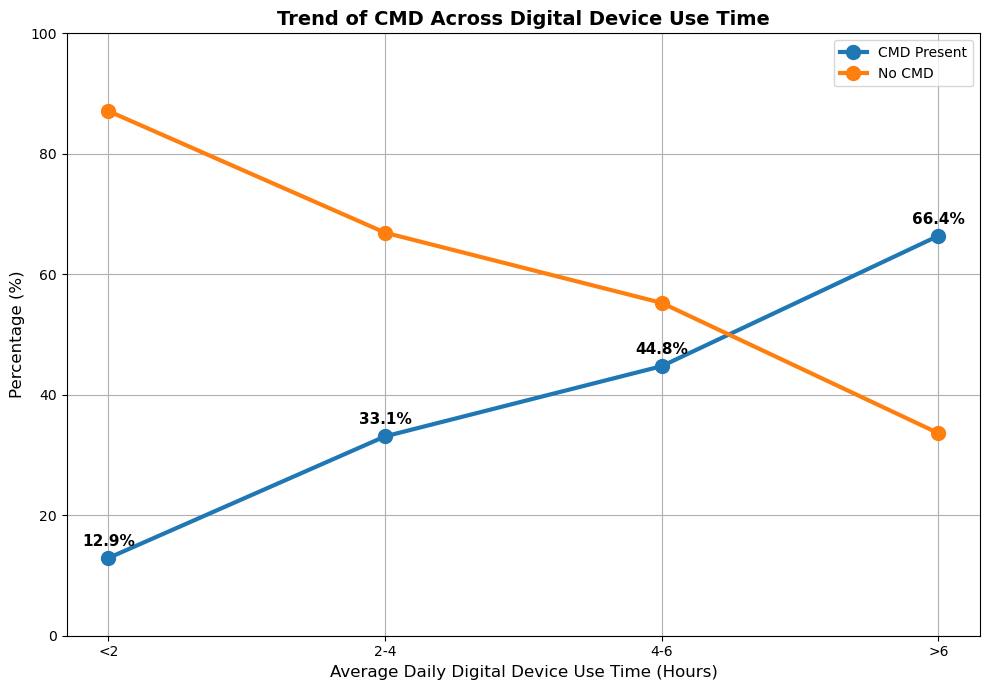

In [90]:
# =========================================================
# CMD TREND VISUALIZATION
# DIGITAL DEVICE USE vs CMD
# PUBLICATION-QUALITY FIGURE
# =========================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# =========================================================
# 1. CREATE TREND TABLE
# =========================================================

trend_table = pd.crosstab(

    df['Average_DD_Use_Time'],
    df['CMD'],

    normalize='index'
) * 100


# =========================================================
# 2. REORDER CATEGORIES
# =========================================================

desired_order = [

    '<2',
    '2-4',
    '4-6',
    '>6'
]

trend_table = trend_table.reindex(desired_order)


# =========================================================
# 3. DISPLAY TABLE
# =========================================================

print("\nCMD TREND TABLE (%)")

print(trend_table)


# =========================================================
# 4. EXPORT TABLE
# =========================================================

trend_table.to_csv(

    'CMD_Trend_Table.csv'
)

print("\nTrend table exported successfully.")


# =========================================================
# 5. CHECK COLUMN NAMES
# =========================================================

print("\nCOLUMN NAMES:")

print(trend_table.columns)


# =========================================================
# 6. EXTRACT VALUES SAFELY
# =========================================================

cmd_present = trend_table.iloc[:, 0].values

no_cmd = trend_table.iloc[:, 1].values


# =========================================================
# 7. CREATE FIGURE
# =========================================================

fig, ax = plt.subplots(figsize=(10,7))


# CMD line

ax.plot(

    desired_order,
    cmd_present,

    marker='o',
    linewidth=3,
    markersize=10,

    label='CMD Present'
)


# No CMD line

ax.plot(

    desired_order,
    no_cmd,

    marker='o',
    linewidth=3,
    markersize=10,

    label='No CMD'
)


# =========================================================
# 8. ADD PERCENTAGE LABELS
# =========================================================

for i, value in enumerate(cmd_present):

    ax.text(

        i,
        value + 2,

        f'{value:.1f}%',

        ha='center',
        fontsize=11,
        fontweight='bold'
    )


# =========================================================
# 9. LABELS
# =========================================================

ax.set_xlabel(

    'Average Daily Digital Device Use Time (Hours)',
    fontsize=12
)

ax.set_ylabel(

    'Percentage (%)',
    fontsize=12
)

ax.set_title(

    'Trend of CMD Across Digital Device Use Time',

    fontsize=14,
    fontweight='bold'
)


# =========================================================
# 10. Y-AXIS LIMIT
# =========================================================

ax.set_ylim(0, 100)


# =========================================================
# 11. GRID
# =========================================================

ax.grid(True)


# =========================================================
# 12. LEGEND
# =========================================================

ax.legend()


# =========================================================
# 13. SAVE TREND FIGURE INTO RESULTS FOLDER
# =========================================================

import os

# Your results folder

OUTPUT_DIR = r'G:\Documents\Book\1\4th Year\4th\1822021 (Project)\Results'

# Create folder if not exists

os.makedirs(OUTPUT_DIR, exist_ok=True)

# Save figure

plt.tight_layout()

plt.savefig(

    os.path.join(

        OUTPUT_DIR,

        'CMD_Trend_Figure.png'
    ),

    dpi=300,
    bbox_inches='tight'
)

print("\nCMD trend figure exported successfully.")

print("\nSaved Location:")

print(

    os.path.join(

        OUTPUT_DIR,

        'CMD_Trend_Figure.png'
    )
)


# =========================================================
# 14. SHOW FIGURE
# =========================================================

plt.show()

In [75]:
import os

print(os.getcwd())

C:\Users\M R Computer
